# Latihan 3 — Support Vector Machine (SVM) Not-OK

**Implementasi SVM kernel linear menggunakan Scikit-learn**

Latihan ini menggunakan data sederhana tentang **lama belajar (Study Hours)** dan **lama tidur (Sleep Hours)** untuk mengklasifikasikan hasil ujian:

- `+1` = Lulus (*Passed*)
- `-1` = Tidak lulus (*Failed*)

Tujuan latihan:
1. Memahami konsep hyperplane, margin, dan support vector.
2. Menghitung persamaan hyperplane secara manual.
3. Membuat model `SVC(kernel='linear')` menggunakan Scikit-learn.
4. Menampilkan decision boundary dan garis margin.

> Notebook ini mengikuti data dan alur pada materi latihan yang diberikan.

## 1. Konsep dasar SVM

Support Vector Machine (SVM) mencari **hyperplane** yang memisahkan dua kelas dengan margin sebesar mungkin. Titik data terdekat terhadap hyperplane disebut **support vectors**.

Untuk dua fitur, persamaan hyperplane linear adalah:

\[
w_1x_1 + w_2x_2 + b = 0
\]

Keterangan:
- \(x_1\): lama belajar.
- \(x_2\): lama tidur.
- \(w_1,w_2\): bobot fitur.
- \(b\): bias/intercept.

Untuk support vector pada margin:

\[
w_1x_1 + w_2x_2 + b = y,
\]

dengan label \(y\) bernilai `+1` atau `-1`.

## 2. Import library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import svm
from fractions import Fraction

print("Library berhasil diimpor.")

Library berhasil diimpor.


## 3. Menyiapkan dataset

Dataset berisi 8 data. Fitur `x1` adalah lama belajar dan `x2` adalah lama tidur. Target `y` menunjukkan hasil ujian.

In [2]:
# Dataset dari materi latihan
x1 = np.array([2, 1, 3, 1, 4, 2, 5, 2])  # Study Hours
x2 = np.array([8, 6, 7, 4, 6, 5, 7, 3])  # Sleep Hours
y = np.array([1, -1, 1, -1, 1, -1, 1, -1])  # Passed Exam

# Menggabungkan dua fitur menjadi matriks X
X = np.column_stack((x1, x2))

# Menampilkan data dalam tabel
df = pd.DataFrame({
    "Study Hours (x1)": x1,
    "Sleep Hours (x2)": x2,
    "Result (y)": y,
    "Class": np.where(y == 1, "Passed", "Failed")
})
df

,Study Hours (x1),Sleep Hours (x2),Result (y),Class
0,2,8,1,Passed
1,1,6,-1,Failed
2,3,7,1,Passed
3,1,4,-1,Failed
4,4,6,1,Passed
5,2,5,-1,Failed
6,5,7,1,Passed
7,2,3,-1,Failed


### Visualisasi data awal

Titik biru adalah kelas lulus (`+1`), sedangkan titik merah adalah kelas tidak lulus (`-1`).

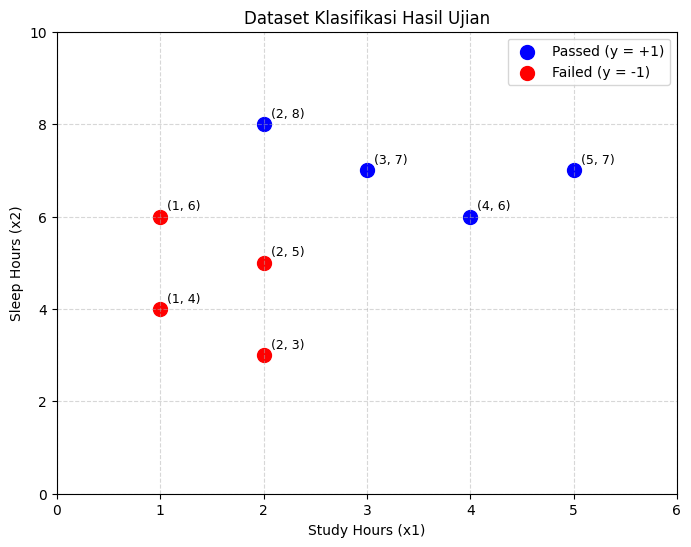

In [3]:
plt.figure(figsize=(8, 6))
plt.scatter(x1[y == 1], x2[y == 1], color="blue", label="Passed (y = +1)", s=100)
plt.scatter(x1[y == -1], x2[y == -1], color="red", label="Failed (y = -1)", s=100)

for i, (a, b) in enumerate(X):
    plt.annotate(f"({a}, {b})", (a, b), xytext=(5, 5), textcoords="offset points", fontsize=9)

plt.title("Dataset Klasifikasi Hasil Ujian")
plt.xlabel("Study Hours (x1)")
plt.ylabel("Sleep Hours (x2)")
plt.xlim(0, 6)
plt.ylim(0, 10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

## 4. Perhitungan manual SVM (kernel linear)

Materi memilih empat support vector berikut:

| Koordinat | Kelas |
|---|---:|
| (3, 7) | +1 |
| (4, 6) | +1 |
| (1, 6) | -1 |
| (2, 5) | -1 |

Masukkan setiap titik ke persamaan margin \(w_1x_1+w_2x_2+b=y\):

\[
\begin{aligned}
3w_1+7w_2+b &= 1 \\
4w_1+6w_2+b &= 1 \\
1w_1+6w_2+b &= -1 \\
2w_1+5w_2+b &= -1
\end{aligned}
\]

**Langkah 1 — Cari hubungan \(w_1\) dan \(w_2\).**

Kurangi persamaan kedua dengan pertama:

\[
(4w_1+6w_2+b)-(3w_1+7w_2+b)=0
\]

\[
w_1-w_2=0 \Rightarrow w_1=w_2
\]

Pengurangan dua persamaan kelas negatif juga menghasilkan \(w_1=w_2\).

**Langkah 2 — Cari bobot dan bias.** Misalkan \(w_1=w_2=w\):

\[
10w+b=1
\]
\[
7w+b=-1
\]

Kurangkan kedua persamaan:

\[
3w=2 \Rightarrow w=\frac{2}{3}
\]

Jadi:

\[
w_1=w_2=\frac{2}{3}
\]

Substitusi ke \(10w+b=1\):

\[
b=1-10\left(\frac{2}{3}\right)=-\frac{17}{3}
\]

**Hasil perhitungan manual:**

\[
w_1=\frac{2}{3},\quad w_2=\frac{2}{3},\quad b=-\frac{17}{3}
\]

### 4.1 Persamaan decision boundary dan margin

Decision boundary diperoleh dari:

\[
\frac{2}{3}x_1+\frac{2}{3}x_2-\frac{17}{3}=0
\]

Kalikan dengan 3 dan susun ulang:

\[
2x_1+2x_2-17=0
\]

\[
\boxed{x_2=-x_1+8.5}
\]

Dua garis margin harus memenuhi \(w_1x_1+w_2x_2+b=+1\) dan \(=-1\):

- Margin kelas positif: \(x_1+x_2=10\), sehingga \(\boxed{x_2=-x_1+10}\).
- Margin kelas negatif: \(x_1+x_2=7\), sehingga \(\boxed{x_2=-x_1+7}\).

> **Catatan koreksi dari materi:** bagian materi yang menuliskan garis margin `x2 = -x1 + 9` dan `x2 = -x1 + 8` tidak konsisten dengan nilai bobot dan bias yang dihitung. Jika memakai \(w_1=w_2=2/3\) dan \(b=-17/3\), garis margin yang benar adalah `x2 = -x1 + 10` dan `x2 = -x1 + 7`. Decision boundary tetap `x2 = -x1 + 8.5`.

> Catatan label: pada satu baris materi, label kelas negatif tertulis `1`; persamaan berikutnya dan array dataset menggunakan `-1`, sehingga notebook ini konsisten memakai `-1` untuk kelas tidak lulus.

In [4]:
# Menampilkan hasil perhitungan manual
w_manual = np.array([2/3, 2/3])
b_manual = -17/3

print("Bobot manual:")
print(f"w1 = {w_manual[0]:.6f}")
print(f"w2 = {w_manual[1]:.6f}")
print(f"Bias (b) = {b_manual:.6f}")
print("Decision boundary: x2 = -x1 + 8.5")
print("Positive margin:   x2 = -x1 + 10")
print("Negative margin:   x2 = -x1 + 7")

Bobot manual:
w1 = 0.666667
w2 = 0.666667
Bias (b) = -5.666667
Decision boundary: x2 = -x1 + 8.5
Positive margin:   x2 = -x1 + 10
Negative margin:   x2 = -x1 + 7


## 5. Implementasi SVM menggunakan Scikit-learn

Gunakan `svm.SVC(kernel="linear")` untuk melatih model. Fungsi `.fit(X, y)` akan mencari bobot dan bias berdasarkan data.

In [5]:
# Membuat dan melatih model SVM dengan kernel linear
clf = svm.SVC(kernel="linear")
clf.fit(X, y)

# Mengambil bobot dan bias dari model
w_sklearn = clf.coef_[0]
b_sklearn = clf.intercept_[0]

print("Bobot dari Scikit-learn:")
print(f"w1 = {w_sklearn[0]:.6f}")
print(f"w2 = {w_sklearn[1]:.6f}")
print(f"Bias (b) = {b_sklearn:.6f}")

Bobot dari Scikit-learn:
w1 = 0.666667
w2 = 0.666667
Bias (b) = -5.666667


### 5.1 Support vectors dari model

Scikit-learn menentukan support vectors berdasarkan seluruh data yang diberikan. Karena titik `(2, 8)` juga berada tepat pada margin kelas positif, model akan menampilkannya sebagai support vector tambahan di samping empat titik yang dipakai dalam contoh perhitungan manual.

In [6]:
support_vectors = clf.support_vectors_
support_indices = clf.support_

print("Indeks support vector:", support_indices)
print("Koordinat support vector:")
print(support_vectors)
print("Label support vector:")
print(y[support_indices])

Indeks support vector: [1 5 0 2 4]
Koordinat support vector:
[[1. 6.]
 [2. 5.]
 [2. 8.]
 [3. 7.]
 [4. 6.]]
Label support vector:
[-1 -1  1  1  1]


### 5.2 Evaluasi hasil prediksi pada data latihan

Bagian ini menampilkan prediksi model untuk delapan data yang sama dengan data latih. Akurasi ini adalah akurasi pada data latih, bukan evaluasi pada data baru.

In [7]:
y_pred = clf.predict(X)

hasil = df.copy()
hasil["Prediksi SVM"] = y_pred
hasil["Keterangan"] = np.where(y_pred == y, "Sesuai", "Tidak sesuai")

print("Akurasi data latih:", f"{clf.score(X, y) * 100:.2f}%")
hasil

Akurasi data latih: 100.00%


,Study Hours (x1),Sleep Hours (x2),Result (y),Class,Prediksi SVM,Keterangan
0,2,8,1,Passed,1,Sesuai
1,1,6,-1,Failed,-1,Sesuai
2,3,7,1,Passed,1,Sesuai
3,1,4,-1,Failed,-1,Sesuai
4,4,6,1,Passed,1,Sesuai
5,2,5,-1,Failed,-1,Sesuai
6,5,7,1,Passed,1,Sesuai
7,2,3,-1,Failed,-1,Sesuai


## 6. Visualisasi decision boundary dan margin

Garis hijau menunjukkan decision boundary. Garis putus-putus menunjukkan margin positif dan negatif.

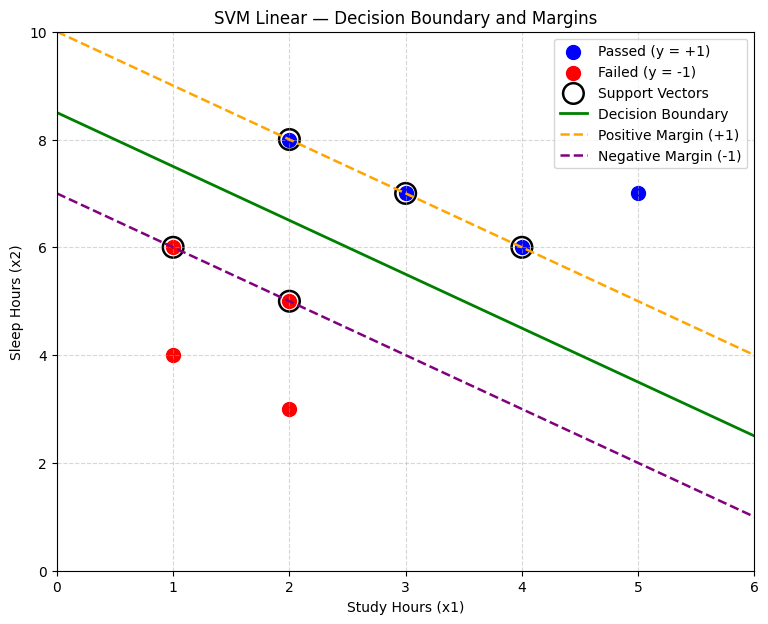

In [8]:
x1_range = np.linspace(0, 6, 200)

# Persamaan garis dihitung dari parameter hasil training
# w1*x1 + w2*x2 + b = 0
# Untuk margin: w1*x1 + w2*x2 + b = +1 atau -1
decision_boundary = -(w_sklearn[0] * x1_range + b_sklearn) / w_sklearn[1]
positive_margin = (1 - b_sklearn - w_sklearn[0] * x1_range) / w_sklearn[1]
negative_margin = (-1 - b_sklearn - w_sklearn[0] * x1_range) / w_sklearn[1]

plt.figure(figsize=(9, 7))
plt.scatter(x1[y == 1], x2[y == 1], color="blue", label="Passed (y = +1)", s=100)
plt.scatter(x1[y == -1], x2[y == -1], color="red", label="Failed (y = -1)", s=100)

# Menandai support vectors
plt.scatter(
    support_vectors[:, 0], support_vectors[:, 1],
    s=220, facecolors="none", edgecolors="black", linewidths=1.8,
    label="Support Vectors"
)

plt.plot(x1_range, decision_boundary, color="green", linewidth=2, label="Decision Boundary")
plt.plot(x1_range, positive_margin, color="orange", linestyle="--", linewidth=1.8, label="Positive Margin (+1)")
plt.plot(x1_range, negative_margin, color="purple", linestyle="--", linewidth=1.8, label="Negative Margin (-1)")

plt.title("SVM Linear — Decision Boundary and Margins")
plt.xlabel("Study Hours (x1)")
plt.ylabel("Sleep Hours (x2)")
plt.xlim(0, 6)
plt.ylim(0, 10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

## 7. Mencoba prediksi data baru

Contoh berikut menggunakan dua data baru: `(3, 8)` dan `(2, 4)`. Model akan memprediksi kelas berdasarkan decision boundary yang sudah dipelajari.

In [9]:
data_baru = np.array([
    [3, 8],  # Study Hours = 3, Sleep Hours = 8
    [2, 4]   # Study Hours = 2, Sleep Hours = 4
])

prediksi_baru = clf.predict(data_baru)

for data, prediksi in zip(data_baru, prediksi_baru):
    status = "Lulus" if prediksi == 1 else "Tidak lulus"
    print(f"Data {tuple(data)} -> Prediksi: {status} (kelas {prediksi:+d})")

Data (np.int64(3), np.int64(8)) -> Prediksi: Lulus (kelas +1)
Data (np.int64(2), np.int64(4)) -> Prediksi: Tidak lulus (kelas -1)


## 8. Perbandingan hasil manual dan Scikit-learn

Hasil model seharusnya sama dengan perhitungan manual untuk bobot, bias, dan decision boundary.

In [10]:
print("Perbandingan parameter:")
print(f"w1 manual       : {w_manual[0]:.6f}")
print(f"w1 Scikit-learn : {w_sklearn[0]:.6f}")
print(f"w2 manual       : {w_manual[1]:.6f}")
print(f"w2 Scikit-learn : {w_sklearn[1]:.6f}")
print(f"b manual        : {b_manual:.6f}")
print(f"b Scikit-learn  : {b_sklearn:.6f}")

print("\nApakah hasil bobot sama?", np.allclose(w_manual, w_sklearn))
print("Apakah hasil bias sama?", np.isclose(b_manual, b_sklearn))

Perbandingan parameter:
w1 manual       : 0.666667
w1 Scikit-learn : 0.666667
w2 manual       : 0.666667
w2 Scikit-learn : 0.666667
b manual        : -5.666667
b Scikit-learn  : -5.666667

Apakah hasil bobot sama? True
Apakah hasil bias sama? True


## 9. Kesimpulan

Berdasarkan latihan ini:

1. SVM kernel linear digunakan untuk memisahkan dua kelas, yaitu lulus (`+1`) dan tidak lulus (`-1`), berdasarkan fitur lama belajar dan lama tidur.
2. Perhitungan manual menghasilkan \(w_1=2/3\), \(w_2=2/3\), dan \(b=-17/3\).
3. Persamaan decision boundary adalah \(x_2=-x_1+8.5\).
4. Garis margin yang konsisten dengan parameter tersebut adalah \(x_2=-x_1+10\) dan \(x_2=-x_1+7\).
5. Implementasi `SVC(kernel="linear")` menghasilkan parameter yang sama. Titik `(2, 8)` juga terdeteksi sebagai support vector karena berada pada margin positif.

**Inti latihan:** memahami konsep SVM melalui perhitungan manual, kemudian membuktikan hasilnya menggunakan Scikit-learn dan visualisasi.